In [29]:
import requests
import pandas as pd
import time
import os

app_id = 394360
cursor = '*'
reviews_list = []
max_reviews = 30000
csv_filename = "hoi4_steam_reviews.csv"

if os.path.exists(csv_filename):
    print(f"'{csv_filename}' zaten mevcut. Dosyadan yükleniyor...")
    df = pd.read_csv(csv_filename)
else:
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
    }
    session = requests.Session()
    session.headers.update(headers)

    print(f"Hearts of Iron IV ({app_id}) için incelemeler çekiliyor...")

    while len(reviews_list) < max_reviews:
        url = f"https://store.steampowered.com/appreviews/{app_id}"
        params = {
            'json': 1,
            'filter': 'recent',
            'language': 'turkish',
            'review_type': 'all',
            'purchase_type': 'all',
            'num_per_page': 100,
            'filter_offtopic_activity': 0,
            'cursor': cursor
        }
        
        try:
            res = session.get(url, params=params, timeout=10)
            data = res.json()
        except Exception as e:
            print(f"Bağlantı hatası: {e}. 2 saniye sonra tekrar deneniyor...")
            time.sleep(2)
            continue

        batch = data.get('reviews', [])
        if not batch:
            print("Çekilecek başka inceleme kalmadı.")
            break

        for r in batch:
            reviews_list.append({
                'review_id': r.get('recommendationid'),
                'review_text': r.get('review', ''),
                'timestamp_created': pd.to_datetime(r.get('timestamp_created'), unit='s'),
                'voted_up': r.get('voted_up'),
                'votes_up': r.get('votes_up'),
                'playtime_hours': round(r.get('author', {}).get('playtime_forever', 0) / 60, 1)
            })

        cursor = data.get('cursor', '*')
        print(f"Toplanan inceleme sayısı: {len(reviews_list)} / {max_reviews}")
        time.sleep(0.5)

    df = pd.DataFrame(reviews_list)
    df.to_csv(csv_filename, index=False, encoding='utf-8-sig')
    print(f"Veri '{csv_filename}' dosyasına kaydedildi!")

print(f"Toplam Veri Sayısı: {len(df)}")
df.head()

'hoi4_steam_reviews.csv' zaten mevcut. Dosyadan yükleniyor...
Toplam Veri Sayısı: 30093


,review_id,review_text,timestamp_created,voted_up,votes_up,playtime_hours
0,236092275,-------,2026-09-24 20:01:54,False,1,689.4
1,236092273,...,2026-09-24 20:01:54,False,1,25.7
2,236092266,"dlc scam ve bugfest, saçma sapan bir oyun.",2026-09-24 20:01:49,False,1,4.8
3,236092263,"Yıllardır binlerce saatimizi gömdüğümüz, her g...",2026-09-24 20:01:49,False,0,16.5
4,236092258,ALAYINIZINAMINAKORUMLAAANORRRROSPUNUNUNCOCUKLA...,2026-09-24 20:01:45,False,0,0.2


In [30]:
df['voted_up'].value_counts(normalize=True)


voted_up
False    0.965939
True     0.034061
Name: proportion, dtype: float64

In [31]:
import re

def clear_text(text):
    if not isinstance(text, str):
        return ""
    text = text.replace('İ', 'i').replace('I', 'ı').lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zçğıöşü\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['review_text'].apply(clear_text)

df_clean = df[df['clean_text'].str.len() > 2].copy()

print(f"Temizleme sonrası kalan yorum sayısı: {len(df_clean)}")
df_clean[['review_text', 'clean_text', 'voted_up']].head(10)

Temizleme sonrası kalan yorum sayısı: 26264


,review_text,clean_text,voted_up
2,"dlc scam ve bugfest, saçma sapan bir oyun.",dlc scam ve bugfest saçma sapan bir oyun,False
3,"Yıllardır binlerce saatimizi gömdüğümüz, her g...",yıllardır binlerce saatimizi gömdüğümüz her ge...,False
4,ALAYINIZINAMINAKORUMLAAANORRRROSPUNUNUNCOCUKLA...,alayınızınamınakorumlaaanorrrrospunununcocukla...,False
5,önce apoya sonra paradoxa,önce apoya sonra paradoxa,False
6,Bu itlerden oyun almayın,bu itlerden oyun almayın,False
7,Tarih oyunu yapıp tarih bilmemekte anca sizin ...,tarih oyunu yapıp tarih bilmemekte anca sizin ...,False
8,Atamın ölüsü bile kudurtmuş sizi kahpe herifler,atamın ölüsü bile kudurtmuş sizi kahpe herifler,False
9,Türk düşmanı olan bütün topluluğun ırkını sikeyim,türk düşmanı olan bütün topluluğun ırkını sikeyim,False
10,This game distorts history. Despite having so ...,this game distorts history despite having so m...,False
11,♥♥♥♥♥♥ game with ♥♥♥♥♥♥ developers,game with developers,False


In [32]:
from collections import Counter
word_counts = Counter(word for text in df_clean['clean_text'] for word in text.split())
for word , count in word_counts.most_common(20):
    print(f"{word}: {count}")

bir: 10402
atatürk: 8585
the: 8334
ve: 8127
bu: 6517
of: 5489
a: 5102
and: 4983
oyun: 4002
türk: 3871
paradox: 3825
kemal: 3537
mustafa: 3467
to: 3461
is: 3051
gibi: 2814
en: 2514
atatürke: 2322
ne: 2259
game: 2253


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

tr_stopwords = [
    'bir', 've', 'bu', 'da', 'de', 'icin', 'için', 'ile', 'ne', 'gibi', 'en', 'cok', 'çok',
    'ama', 'kadar', 'daha', 'ben', 'sen', 'o', 'biz', 'siz', 'onlar', 'bunu', 'buna', 'her',
    'mi', 'mu', 'mı', 'mü', 'ya', 'ye', 'bile', 'diye', 'ise', 'ki',
    'the', 'and', 'of', 'to', 'a', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on'
]
tfidf = TfidfVectorizer(stop_words=tr_stopwords,ngram_range=(1, 2), max_features=2500,min_df=5, max_df=0.5)
X= tfidf.fit_transform(df_clean['clean_text'])
y= df_clean['voted_up'].astype(int)
print("TF-IDF matrisi oluşturuldu. Boyutlar:", X.shape)

TF-IDF matrisi oluşturuldu. Boyutlar: (26264, 2500)


In [36]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42,n_init=10)
kmeans.fit(X)
terms=tfidf.get_feature_names_out()
ordered_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
print("Kümeleme tamamlandı. Küme başlıkları:")
for i in range(3):
    top_words = [terms[ind] for ind in ordered_centroids[i, :10]]
    print(f"\nKüme {i+1}:")
    print(" - " + "\n - ".join(top_words))

Kümeleme tamamlandı. Küme başlıkları:

Küme 1:
 - atatürk
 - paradox
 - atatürke
 - oyunu
 - game
 - türk
 - boykot
 - kötü
 - orospu
 - mustafa

Küme 2:
 - atatürk
 - kemal atatürk
 - kemal
 - mustafa kemal
 - mustafa
 - sunucusunda atatürk
 - yıllarca
 - allah razı
 - razı
 - razı olsun

Küme 3:
 - oyun
 - bok
 - çöp
 - bok oyun
 - kötü
 - kötü oyun
 - berbat
 - berbat oyun
 - rezalet
 - almayın


--- SINIFLANDIRMA PERFORMANS RAPORU ---
              precision    recall  f1-score   support

Negative (0)       0.99      0.87      0.93      5059
Positive (1)       0.20      0.84      0.32       194

    accuracy                           0.87      5253
   macro avg       0.60      0.85      0.62      5253
weighted avg       0.96      0.87      0.90      5253



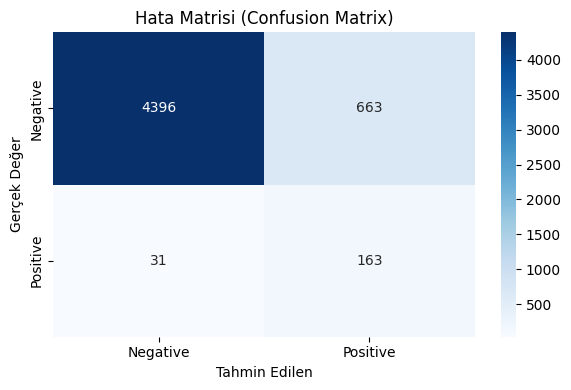

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("--- SINIFLANDIRMA PERFORMANS RAPORU ---")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Positive'], 
            yticklabels=['Negative', 'Positive'])
plt.title('Hata Matrisi (Confusion Matrix)')
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.tight_layout()
plt.show()

In [38]:
import numpy as np
import matplotlib.pyplot as plt
feature_names = np.array(tfidf.get_feature_names_out())
coefs=model.coef_[0]
top_pos_idx=coefs.argsort()[-10:][::-1]
top_neg_idx=coefs.argsort()[:10]
print("--- Top 10 Pozitif (Olumluya İten) Kelimeler ---")
for idx in top_pos_idx:
    print(f"{feature_names[idx]:<20}: {coefs[idx]:.4f}")

print("\n--- Top 10 Negatif (Olumsuza İten) Kelimeler ---")
for idx in top_neg_idx:
    print(f"{feature_names[idx]:<20}: {coefs[idx]:.4f}")
    

--- Top 10 Pozitif (Olumluya İten) Kelimeler ---
güzel               : 3.4131
saat                : 3.2911
iyi                 : 3.2262
great               : 3.1541
oyundur             : 2.9288
hala                : 2.7839
donanma             : 2.6955
oynamayı            : 2.6928
yeni                : 2.6596
oynayın             : 2.6520

--- Top 10 Negatif (Olumsuza İten) Kelimeler ---
atatürke            : -5.5620
atatürk             : -5.0746
kötü                : -4.6338
özür                : -4.5829
atatürkü            : -4.4617
ırkçı               : -4.4086
türk                : -4.2380
berbat              : -4.1336
boykot              : -3.9434
zaten               : -3.8162


In [ ]:
ornek_yorumlar = [
    "Oyun tarih simülasyonu olarak harika, saatlerce başından kalkamıyorum kesinlikle tavsiye ederim.",
    "Paradox discordunda Atatürk fotoğrafına yapılan saygısızlık affedilemez, oyunu siliyorum.",
    "Güzel oyun ama son olaylardan dolayı param haram olsun rezalet."
]

temiz_ornekler = [clear_text(y) for y in ornek_yorumlar]

ornek_vektor = tfidf.transform(temiz_ornekler)
tahminler = model.predict(ornek_vektor)
olasiliklar = model.predict_proba(ornek_vektor)

print("--- CANLI TEST SONUÇLARI ---")
for yorum, t, p in zip(ornek_yorumlar, tahminler, olasiliklar):
    etiket = "OLUMLU (1)" if t == 1 else "OLUMSUZ (0)"
    print(f"\nYorum: '{yorum}'")
    print(f"Tahmin: {etiket} | Olumsuzluk: %{p[0]*100:.1f} - Olumluluk: %{p[1]*100:.1f}")

--- CANLI TEST SONUÇLARI ---

Yorum: 'Oyun tarih simülasyonu olarak harika, saatlerce başından kalkamıyorum kesinlikle tavsiye ederim.'
Tahmin: OLUMLU (1) | Olumsuzluk: %10.4 - Olumluluk: %89.6

Yorum: 'Paradox discordunda Atatürk fotoğrafına yapılan saygısızlık affedilemez, oyunu siliyorum.'
Tahmin: OLUMSUZ (0) | Olumsuzluk: %97.3 - Olumluluk: %2.7

Yorum: 'Güzel oyun ama son olaylardan dolayı param haram olsun rezalet.'
Tahmin: OLUMLU (1) | Olumsuzluk: %42.6 - Olumluluk: %57.4


In [41]:
import numpy as np
import pandas as pd 
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

reg_df = df_clean.copy()

reg_df['char_length']=reg_df['review_text'].str.len()
reg_df['word_count']=reg_df['review_text'].str.split().apply(len)

probs=model.predict_proba(X)
reg_df['negative_prob']=probs[:,0]

features=['char_length', 'word_count', 'negative_prob','playtime_hours']
X_reg=reg_df[features].fillna(0)
y_reg=reg_df['votes_up']

X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
reg_model=Ridge()
reg_model.fit(X_train, y_train)
y_pred=reg_model.predict(X_test)

rmse=np.sqrt(mean_squared_error(y_test, y_pred))
r2=r2_score(y_test, y_pred)
print(f"--- RIDGE REGRESYON SONUÇLARI ---")
print(f"RMSE (Kök Ortalama Kare Hata) : {rmse:.2f}")
print(f"R² Skoru (Açıklanan Varyans)   : {r2:.4f}\n")

print("--- Özellik Katsayıları ---")
for feat, coef in zip(features, reg_model.coef_):
    print(f"Özellik: {feat:<18} -> Katsayı: {coef:.4f}")

--- RIDGE REGRESYON SONUÇLARI ---
RMSE (Kök Ortalama Kare Hata) : 129.54
R² Skoru (Açıklanan Varyans)   : 0.0032

--- Özellik Katsayıları ---
Özellik: char_length        -> Katsayı: 0.0015
Özellik: word_count         -> Katsayı: 0.0414
Özellik: negative_prob      -> Katsayı: 6.4006
Özellik: playtime_hours     -> Katsayı: 0.0019


In [42]:
negative_hours = df_clean[df_clean['voted_up'] == False]['playtime_hours']
positive_hours = df_clean[df_clean['voted_up'] == True]['playtime_hours']

print("--- OYUNCU SADAKATİ ANALİZİ ---")
print(f"Olumsuz Yorum Yazanların Ortalama Saati : {negative_hours.mean():.1f} saat")
print(f"Olumsuz Yorum Yazanların Medyan Saati   : {negative_hours.median():.1f} saat")
print(f"Olumlu Yorum Yazanların Ortalama Saati  : {positive_hours.mean():.1f} saat")
print(f"Olumlu Yorum Yazanların Medyan Saati    : {positive_hours.median():.1f} saat")

hours_100 = (negative_hours >= 100).mean() * 100
print(f"\nOlumsuz Yazanlar Arasında 100+ Saat Oynayanlar: %{hours_100:.2f}")

--- OYUNCU SADAKATİ ANALİZİ ---
Olumsuz Yorum Yazanların Ortalama Saati : 231.5 saat
Olumsuz Yorum Yazanların Medyan Saati   : 34.5 saat
Olumlu Yorum Yazanların Ortalama Saati  : 356.6 saat
Olumlu Yorum Yazanların Medyan Saati    : 165.3 saat

Olumsuz Yazanlar Arasında 100+ Saat Oynayanlar: %37.29


In [43]:
import joblib

joblib.dump(model, 'sentiment_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
print("Model ve TF-IDF vektörleştirici başarıyla kaydedildi: 'sentiment_model.pkl', 'tfidf_vectorizer.pkl'")

Model ve TF-IDF vektörleştirici başarıyla kaydedildi: 'sentiment_model.pkl', 'tfidf_vectorizer.pkl'


C:\Users\kerim\AppData\Local\Temp\ipykernel_13340\1835076801.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


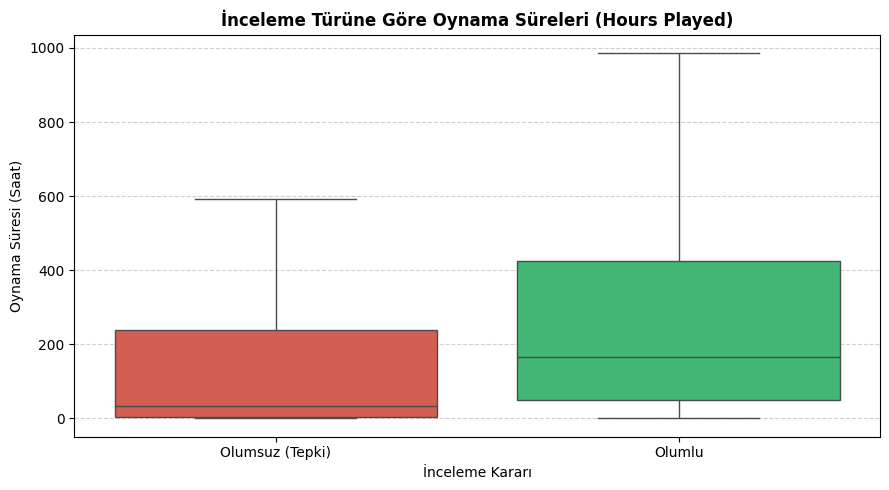

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.boxplot(
    x='voted_up', 
    y='playtime_hours', 
    data=df_clean, 
    showfliers=False,
    palette=['#e74c3c', '#2ecc71']
)
plt.xticks([0, 1], ['Olumsuz (Tepki)', 'Olumlu'])
plt.title('İnceleme Türüne Göre Oynama Süreleri (Hours Played)', fontsize=12, fontweight='bold')
plt.xlabel('İnceleme Kararı')
plt.ylabel('Oynama Süresi (Saat)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

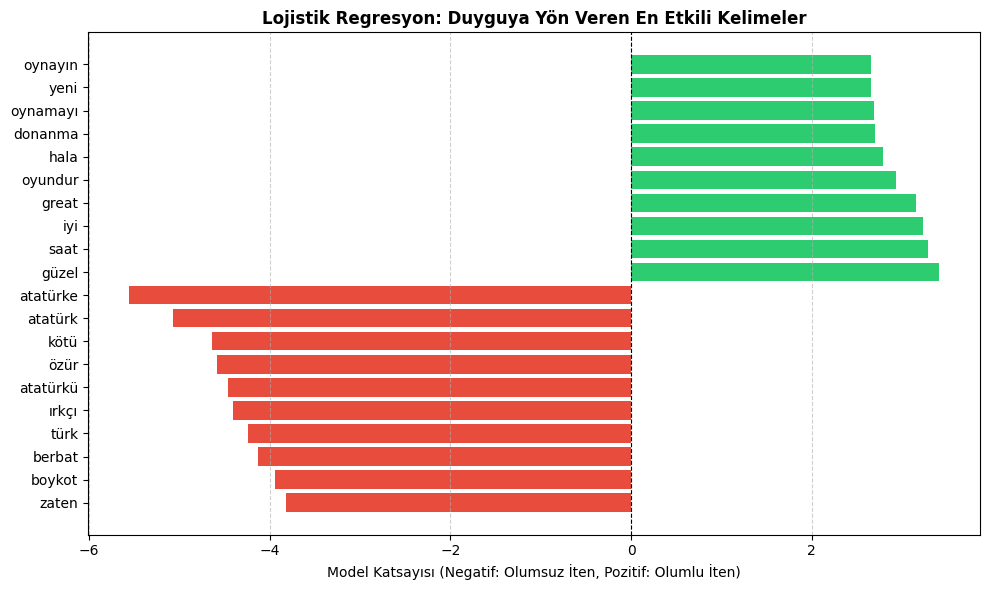

In [45]:
plt.figure(figsize=(10, 6))

words = list(feature_names[top_neg_idx][::-1]) + list(feature_names[top_pos_idx])
values = list(coefs[top_neg_idx][::-1]) + list(coefs[top_pos_idx])
bar_colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in values]

plt.barh(words, values, color=bar_colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Lojistik Regresyon: Duyguya Yön Veren En Etkili Kelimeler', fontsize=12, fontweight='bold')
plt.xlabel('Model Katsayısı (Negatif: Olumsuz İten, Pozitif: Olumlu İten)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()